# Players Dataset — Detailed EDA and Cleaning

## Objective

This notebook reviews the supplied player reference dataset in a deliberate, human-readable sequence: understand the records, establish data quality, investigate each field, inspect suspicious values, make only justified cleaning changes, validate the result, and export a cleaned CSV.

**Working interpretation:** each row represents one player record. The dataset has six fields: `player_id`, `player_name`, `bat_style`, `bowl_style`, `field_pos`, and `player_full_name`.

**Cleaning principles**
- Preserve an unchanged copy of the original data.
- Do not remove players just because descriptive fields are missing.
- Convert whitespace-only text to proper missing values.
- Do not invent bowling styles or field positions.
- Treat unexpected values as investigation points, not automatic errors.
- Export only after explicit validation.

## 1. Load the file and protect the original data

First, confirm that the correct file is loaded and inspect its size. The path below assumes the CSV is in the same folder as this notebook. If it is stored elsewhere, update `DATA_PATH`.

In [4]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

DATA_PATH = Path("../../players-data-updated.csv")

OUTPUT_DIR = Path("../../data/cleaned")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_PATH = OUTPUT_DIR / "players-data-updated_clean.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Source CSV not found: {DATA_PATH.resolve()}")

df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy(deep=True)

print(f"Loaded file: {DATA_PATH.resolve()}")
print(f"Rows: {len(df):,}")
print(f"Columns: {df.shape[1]}")
print(f"Memory usage: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

Loaded file: C:\Users\Bhuvan\Desktop\IPL DATA\players-data-updated.csv
Rows: 799
Columns: 6
Memory usage: 0.08 MB


### First observation: what does a record look like?

Review the first and last few rows and the column names. This helps catch obvious parsing issues before we draw conclusions about missingness or uniqueness.

In [5]:
display(df.head(8))
display(df.tail(5))
print("Columns:", df.columns.tolist())

,player_id,player_name,bat_style,bowl_style,field_pos,player_full_name
0,963,MN Samuels,Right hand Bat,Right arm Offbreak,,Marlon Nathaniel Samuels
1,53,SB Jakati,Left hand Bat,Slow Left arm Orthodox,,Shadab Bashir Jakati
2,12,DA Warner,Left hand Bat,Legbreak,,David Andrew Warner
3,268,RA Tripathi,Right hand Bat,Right arm Medium,,Rahul Ajay Tripathi
4,186,S Nadeem,Right hand Bat,Slow Left arm Orthodox,,Shahbaz Nadeem
5,59,MK Pandey,Right hand Bat,Right arm Medium,,Manish Krishnanand Pandey
6,531,KS Williamson,Right hand Bat,Right arm Offbreak,,Kane Stuart Williamson
7,56,G Gambhir,Left hand Bat,Legbreak,,Gautam Gambhir


,player_id,player_name,bat_style,bowl_style,field_pos,player_full_name
794,8475,Suyash Sharma,Right hand Bat,Legbreak Googly,,Suyash Sharma
795,45004,D Madushanka,Right hand Bat,Right arm Medium fast,NaN,K Dasun Madusanka
796,42566,V Suryavanshi,Left hand Bat,Slow Left arm Orthodox,NaN,Vaibhav Suryavanshi
797,26,N Rana,Left hand Bat,"Right arm Medium, Right arm Offbreak, Legbreak",,Nitish Rana
798,45986,SU Parakh,Left hand Bat,Legbreak,NaN,Sahil Ulhas Parakh


Columns: ['player_id', 'player_name', 'bat_style', 'bowl_style', 'field_pos', 'player_full_name']


## 2. Establish a baseline

Before examining individual columns, summarize data types, missing values, distinct values, and general statistics. This tells us where to focus the detailed investigation.

In [6]:
structure = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_missing": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique_non_missing": df.nunique(dropna=True)
})
display(structure)

,dtype,non_missing,missing,missing_pct,unique_non_missing
player_id,int64,799,0,0.00,799
player_name,str,799,0,0.00,799
bat_style,str,799,0,0.00,2
bowl_style,str,780,19,2.38,23
field_pos,str,711,88,11.01,7
player_full_name,str,799,0,0.00,799


In [7]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
player_id,799.0,NaN,NaN,NaN,12211.902378,12671.682814,1.0,2305.0,10160.0,13997.0,45986.0
player_name,799,799,MN Samuels,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bat_style,799,2,Right hand Bat,582,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bowl_style,780,23,Right arm Medium,141,NaN,NaN,NaN,NaN,NaN,NaN,NaN
field_pos,711,7,,612,NaN,NaN,NaN,NaN,NaN,NaN,NaN
player_full_name,799,799,Marlon Nathaniel Samuels,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,missing_count,missing_pct
field_pos,88,11.01
bowl_style,19,2.38


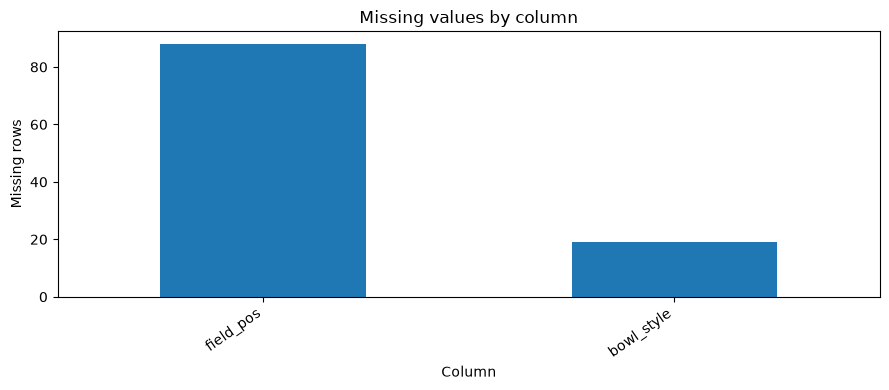

In [8]:
missing_summary = (
    pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_pct": (df.isna().mean() * 100).round(2)
    })
    .query("missing_count > 0")
    .sort_values("missing_count", ascending=False)
)
display(missing_summary)

if not missing_summary.empty:
    ax = missing_summary["missing_count"].plot(
        kind="bar", figsize=(9, 4), title="Missing values by column"
    )
    ax.set_xlabel("Column")
    ax.set_ylabel("Missing rows")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

## 3. Check the row grain and player identifier

If each row is intended to describe one player, `player_id` should be present and unique. We check exact duplicate rows separately from duplicate IDs because they indicate different problems. We also inspect the ID range, but do not assume IDs must be consecutive; reference IDs often contain gaps.

In [9]:
print(f"Missing player_id values: {df['player_id'].isna().sum():,}")
print(f"Unique player_id values: {df['player_id'].nunique(dropna=True):,}")
print(f"Duplicate player_id rows: {df['player_id'].duplicated().sum():,}")
print(f"Exact duplicate rows: {df.duplicated().sum():,}")
print(f"player_id range: {df['player_id'].min()} to {df['player_id'].max()}")

if df["player_id"].duplicated().any():
    display(df[df["player_id"].duplicated(keep=False)].sort_values("player_id"))

Missing player_id values: 0
Unique player_id values: 799
Duplicate player_id rows: 0
Exact duplicate rows: 0
player_id range: 1 to 45986


**Interpretation:** a gap in player IDs is not, by itself, a quality problem. The key requirement for this file is that each record has one identifiable player ID and that the ID is not repeated unexpectedly.

## 4. Investigate player names

`player_name` and `player_full_name` appear to serve different purposes: one is a display/short name and the other is a longer name. Check missingness, blank strings, duplicate names, and whether a player ID maps to more than one name. Do not merge records based on names alone; the ID is the stronger identifier in this file.

In [10]:
name_columns = ["player_name", "player_full_name"]
for col in name_columns:
    print(f"--- {col} ---")
    print("Missing:", int(df[col].isna().sum()))
    print("Distinct non-missing values:", int(df[col].nunique(dropna=True)))
    print("Duplicate non-missing values:", int(df[col].dropna().duplicated().sum()))
    display(df[col].value_counts(dropna=False).head(10).to_frame("rows"))

--- player_name ---
Missing: 0
Distinct non-missing values: 799
Duplicate non-missing values: 0


,rows
player_name,
MN Samuels,1
SB Jakati,1
DA Warner,1
RA Tripathi,1
S Nadeem,1
MK Pandey,1
KS Williamson,1
G Gambhir,1
MK Tiwary,1


--- player_full_name ---
Missing: 0
Distinct non-missing values: 799
Duplicate non-missing values: 0


,rows
player_full_name,
Marlon Nathaniel Samuels,1
Shadab Bashir Jakati,1
David Andrew Warner,1
Rahul Ajay Tripathi,1
Shahbaz Nadeem,1
Manish Krishnanand Pandey,1
Kane Stuart Williamson,1
Gautam Gambhir,1
Manoj Kumar Tiwary,1


In [11]:
# Check whether one player_id has conflicting values in either name field.
name_consistency = df.groupby("player_id", dropna=False).agg(
    short_name_values=("player_name", "nunique"),
    full_name_values=("player_full_name", "nunique")
)
conflicting_name_ids = name_consistency[
    (name_consistency["short_name_values"] > 1) |
    (name_consistency["full_name_values"] > 1)
]
print(f"Player IDs with conflicting names: {len(conflicting_name_ids):,}")
if len(conflicting_name_ids):
    display(conflicting_name_ids)

Player IDs with conflicting names: 0


## 5. Investigate batting style

Batting style is a categorical attribute. First check whether values are missing, blank, or inconsistent in spelling/format. Then inspect the category counts. A category imbalance is descriptive, not necessarily an error, and values should not be recoded without evidence that they represent the same category.

In [12]:
print("Missing batting styles:", int(df["bat_style"].isna().sum()))
print("Batting style counts:")
display(df["bat_style"].value_counts(dropna=False).to_frame("players"))

Missing batting styles: 0
Batting style counts:


,players
bat_style,
Right hand Bat,582
Left hand Bat,217


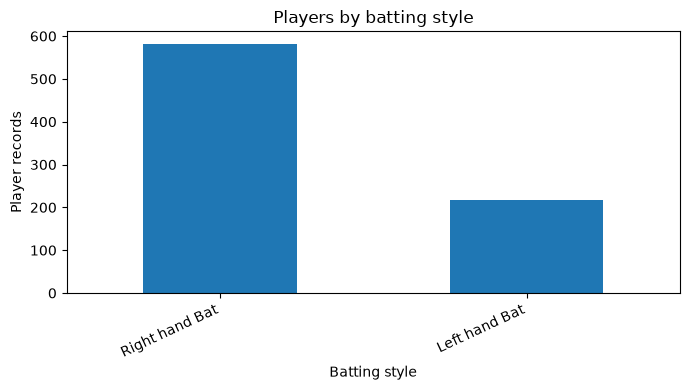

In [13]:
ax = df["bat_style"].value_counts(dropna=False).plot(
    kind="bar", figsize=(7, 4), title="Players by batting style"
)
ax.set_xlabel("Batting style")
ax.set_ylabel("Player records")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 6. Investigate bowling style and blank values

Bowling style is optional for some players, especially players who do not bowl or whose style was not recorded. The source also contains whitespace-only strings, which look blank but are not treated as null by pandas. Count true nulls and whitespace-only values separately before cleaning; do not replace missing styles with a guessed category.

In [14]:
bowl_text = df["bowl_style"].astype("string")
bowl_whitespace_only = bowl_text.notna() & bowl_text.str.strip().eq("")
print("Bowling style nulls in raw CSV:", int(df["bowl_style"].isna().sum()))
print("Bowling style whitespace-only values:", int(bowl_whitespace_only.sum()))
print("Bowling style non-blank categories:")
display(
    df.loc[~bowl_whitespace_only, "bowl_style"]
    .value_counts(dropna=False)
    .head(25)
    .to_frame("players")
)

Bowling style nulls in raw CSV: 19
Bowling style whitespace-only values: 54
Bowling style non-blank categories:


,players
bowl_style,
Right arm Medium,141
Right arm Offbreak,129
Right arm Fast medium,83
Slow Left arm Orthodox,68
Right arm Medium fast,60
Right arm Fast,52
Legbreak,48
Legbreak Googly,41
Left arm Fast medium,27


In [15]:
# Display bowling style categories after a temporary trim to reveal formatting variants.
bowl_trimmed = df["bowl_style"].astype("string").str.strip().replace("", pd.NA)
print("Distinct non-missing bowling styles before trim:", df["bowl_style"].nunique(dropna=True))
print("Distinct non-missing bowling styles after trim:", bowl_trimmed.nunique(dropna=True))
display(bowl_trimmed.value_counts(dropna=False).head(25).to_frame("players"))

Distinct non-missing bowling styles before trim: 23
Distinct non-missing bowling styles after trim: 22


,players
bowl_style,
Right arm Medium,141
Right arm Offbreak,129
Right arm Fast medium,83
<NA>,73
Slow Left arm Orthodox,68
Right arm Medium fast,60
Right arm Fast,52
Legbreak,48
Legbreak Googly,41


**Interpretation:** trimming reveals the actual category values without changing their meaning. A style label that differs only by capitalization or wording should not be merged automatically unless the source convention confirms that the labels are equivalent.

## 7. Investigate field position

`field_pos` is especially important to inspect because most values in the supplied file are blank/whitespace, while a smaller number contain values such as wicketkeeper labels. A few non-blank values appear to be bowling-style descriptions rather than field positions. These records are suspicious, but this file alone does not tell us whether the values were misplaced during source preparation.

We will list the non-blank values and their player IDs, then normalize blank text to missing. We will not move or delete values without checking the upstream source.

In [16]:
field_text = df["field_pos"].astype("string")
field_blank = field_text.notna() & field_text.str.strip().eq("")
field_nonblank = field_text.notna() & field_text.str.strip().ne("")

print("Raw null field_pos values:", int(df["field_pos"].isna().sum()))
print("Whitespace-only field_pos values:", int(field_blank.sum()))
print("Non-blank field_pos values:", int(field_nonblank.sum()))
display(
    df.loc[field_nonblank, ["player_id", "player_name", "bowl_style", "field_pos", "player_full_name"]]
    .sort_values(["field_pos", "player_name"])
)

Raw null field_pos values: 88
Whitespace-only field_pos values: 612
Non-blank field_pos values: 99


,player_id,player_name,bowl_style,field_pos,player_full_name
471,1970,AD Hales,Right arm Medium,Occasional Wicketkeeper,Alexander Daniel Hales
357,27,AT Rayudu,Right arm Offbreak,Occasional Wicketkeeper,Ambati Thirupathi Rayudu
344,36311,BJ Rohrer,,Occasional Wicketkeeper,Ben James Rohrer
240,12518,CK Kapugedera,Right arm Medium,Occasional Wicketkeeper,Chamara Kantha Kapugedera
565,697,DM Bravo,Right arm Medium,Occasional Wicketkeeper,Darren Michael Bravo
...,...,...,...,...,...
468,43548,Urvil Patel,NaN,Wicketkeeper,Urvil Mukesh Patel
42,171,Vishnu Vinod,,Wicketkeeper,Vishnu Vinod
317,69,WP Saha,,Wicketkeeper,Wriddhiman Prasanta Saha
473,12414,YV Takawale,,Wicketkeeper,Yogesh Vijay Takawale


In [17]:
print("Field position value counts, including blanks and nulls:")
display(df["field_pos"].value_counts(dropna=False).to_frame("rows"))

Field position value counts, including blanks and nulls:


,rows
field_pos,
,612
NaN,88
Wicketkeeper,82
Occasional Wicketkeeper,13
Right arm Medium,1
Right arm Fast,1
Slow Left arm Orthodox,1
Wicketkeeper Batter,1


## 8. Inspect text quality across all text columns

Before cleaning, quantify leading/trailing whitespace and whitespace-only strings for every text column. This makes the cleaning step evidence-based rather than arbitrary.

In [18]:
text_columns = df.select_dtypes(include=["object", "string"]).columns.tolist()
text_quality = []
for col in text_columns:
    s = df[col].astype("string")
    non_missing = s.notna()
    text_quality.append({
        "column": col,
        "non_missing": int(non_missing.sum()),
        "leading_or_trailing_whitespace": int((non_missing & s.ne(s.str.strip())).sum()),
        "whitespace_only": int((non_missing & s.str.strip().eq("")).sum()),
        "distinct_values": int(df[col].nunique(dropna=True))
    })
display(pd.DataFrame(text_quality).set_index("column"))

,non_missing,leading_or_trailing_whitespace,whitespace_only,distinct_values
column,,,,
player_name,799,0,0,799
bat_style,799,0,0,2
bowl_style,780,54,54,23
field_pos,711,612,612,7
player_full_name,799,0,0,799


## 9. Review missingness by attribute

Now combine the evidence from the individual fields. Missing `bowl_style` and `field_pos` should remain missing unless a trusted source can supply the values. The short and full name fields and the player identifier are more fundamental, so any missing values there would need investigation before export.

In [19]:
missing_by_field = pd.DataFrame({
    "raw_nulls": df_raw.isna().sum(),
    "raw_null_pct": (df_raw.isna().mean() * 100).round(2),
    "whitespace_only": {
        col: int((
            df_raw[col].astype("string").notna() &
            df_raw[col].astype("string").str.strip().eq("")
        ).sum())
        for col in text_columns
    }
})
display(missing_by_field)

,raw_nulls,raw_null_pct,whitespace_only
bat_style,0,0.00,0.0
bowl_style,19,2.38,54.0
field_pos,88,11.01,612.0
player_full_name,0,0.00,0.0
player_id,0,0.00,NaN
player_name,0,0.00,0.0


## 10. Cleaning decisions

Based on the checks above, the defensible transformations are limited:

1. Strip leading and trailing whitespace from text columns.
2. Convert whitespace-only strings to proper missing values.
3. Keep all 799 player records; do not drop rows for missing optional attributes.
4. Preserve numeric player IDs and name values rather than trying to reconstruct identities.
5. Do not guess missing bowling styles or field positions.
6. Retain the suspicious non-blank `field_pos` values but document them for source review.

In [20]:
df_clean = df_raw.copy(deep=True)
clean_text_columns = df_clean.select_dtypes(include=["object", "string"]).columns.tolist()

for col in clean_text_columns:
    df_clean[col] = df_clean[col].astype("string").str.strip()
    df_clean[col] = df_clean[col].replace("", pd.NA)

print("Original shape:", df_raw.shape)
print("Cleaned shape:", df_clean.shape)
print("Rows removed:", len(df_raw) - len(df_clean))
print("Exact duplicate rows before:", int(df_raw.duplicated().sum()))
print("Exact duplicate rows after:", int(df_clean.duplicated().sum()))
print("Text columns normalized:", clean_text_columns)

Original shape: (799, 6)
Cleaned shape: (799, 6)
Rows removed: 0
Exact duplicate rows before: 0
Exact duplicate rows after: 0
Text columns normalized: ['player_name', 'bat_style', 'bowl_style', 'field_pos', 'player_full_name']


## 11. Validate the cleaned dataset

Repeat the key integrity checks after normalization. These checks confirm that the transformation did not remove records, damage the ID key, or leave whitespace-only text values. They do not prove that every source attribute is semantically correct.

In [21]:
final_checks = {
    "row_count_unchanged": len(df_clean) == len(df_raw),
    "column_count_unchanged": df_clean.shape[1] == df_raw.shape[1],
    "player_id_has_no_missing_values": bool(df_clean["player_id"].notna().all()),
    "player_id_is_unique": bool(df_clean["player_id"].is_unique),
    "no_exact_duplicate_rows": int(df_clean.duplicated().sum()) == 0,
    "player_name_has_no_missing_values": bool(df_clean["player_name"].notna().all()),
    "player_full_name_has_no_missing_values": bool(df_clean["player_full_name"].notna().all()),
    "no_whitespace_only_text_values": bool(all(
        not (
            df_clean[col].astype("string").notna() &
            df_clean[col].astype("string").str.strip().eq("")
        ).any()
        for col in clean_text_columns
    )),
    "no_leading_trailing_whitespace": bool(all(
        not (
            df_clean[col].dropna().astype("string")
            .ne(df_clean[col].dropna().astype("string").str.strip())
        ).any()
        for col in clean_text_columns
    ))
}
validation = pd.DataFrame({"passed": pd.Series(final_checks)})
display(validation)
print(f"Checks passed: {sum(final_checks.values())}/{len(final_checks)}")
failed_checks = [name for name, passed in final_checks.items() if not passed]
if failed_checks:
    raise AssertionError(f"Final validation failed: {failed_checks}")

,passed
row_count_unchanged,True
column_count_unchanged,True
player_id_has_no_missing_values,True
player_id_is_unique,True
no_exact_duplicate_rows,True
player_name_has_no_missing_values,True
player_full_name_has_no_missing_values,True
no_whitespace_only_text_values,True
no_leading_trailing_whitespace,True


Checks passed: 9/9


## 12. Record unresolved questions

A clean CSV can still contain source-level ambiguity. This issue register keeps those questions visible rather than silently making assumptions.

In [22]:
issue_register = pd.DataFrame([
    {
        "topic": "missing bowling styles",
        "evidence": f"{int(df_clean['bowl_style'].isna().sum())} missing after blank normalization.",
        "decision": "Retain missing values.",
        "follow_up": "Fill only from a trusted player reference source if bowling-style analysis requires it."
    },
    {
        "topic": "field_pos sparsity",
        "evidence": f"{int(df_clean['field_pos'].isna().sum())} missing after blank normalization.",
        "decision": "Retain missing values.",
        "follow_up": "Confirm what this field represents and whether blank means not applicable or not recorded."
    },
    {
        "topic": "unexpected field_pos labels",
        "evidence": "Some non-blank field_pos entries appear to be bowling-style descriptions rather than field positions.",
        "decision": "Preserve the original values.",
        "follow_up": "Compare these player IDs against the upstream source before correcting or moving any values."
    },
    {
        "topic": "player ID gaps",
        "evidence": f"Player IDs range from {df_clean['player_id'].min()} to {df_clean['player_id'].max()}.",
        "decision": "Do not renumber IDs.",
        "follow_up": "Gaps are not errors by themselves; retain IDs for joins to other source tables."
    }
])
display(issue_register)

,topic,evidence,decision,follow_up
0,missing bowling styles,73 missing after blank normalization.,Retain missing values.,Fill only from a trusted player reference sour...
1,field_pos sparsity,700 missing after blank normalization.,Retain missing values.,Confirm what this field represents and whether...
2,unexpected field_pos labels,Some non-blank field_pos entries appear to be ...,Preserve the original values.,Compare these player IDs against the upstream ...
3,player ID gaps,Player IDs range from 1 to 45986.,Do not renumber IDs.,Gaps are not errors by themselves; retain IDs ...


## 13. Export the cleaned CSV

The export writes the cleaned dataframe without an extra pandas index column. It preserves the original six-column schema and every player record. After export, the file is reloaded to verify its shape and column order.

In [23]:
if failed_checks:
    raise AssertionError(f"Export stopped because final validation failed: {failed_checks}")

df_clean.to_csv(OUTPUT_PATH, index=False, encoding="utf-8")

print(f"Cleaned CSV exported to: {OUTPUT_PATH.resolve()}")
print(f"Rows exported: {len(df_clean):,}")
print(f"Columns exported: {df_clean.shape[1]}")
print(f"File size: {OUTPUT_PATH.stat().st_size / (1024 ** 2):.2f} MB")

Cleaned CSV exported to: C:\Users\Bhuvan\Desktop\IPL DATA\data\cleaned\players-data-updated_clean.csv
Rows exported: 799
Columns exported: 6
File size: 0.05 MB


In [24]:
df_export_check = pd.read_csv(OUTPUT_PATH)
shape_matches = df_export_check.shape == df_clean.shape
columns_match = df_export_check.columns.tolist() == df_clean.columns.tolist()

print("Reloaded CSV shape:", df_export_check.shape)
print("Shape matches:", shape_matches)
print("Column order matches:", columns_match)
assert shape_matches and columns_match
display(df_export_check.head(5))

Reloaded CSV shape: (799, 6)
Shape matches: True
Column order matches: True


,player_id,player_name,bat_style,bowl_style,field_pos,player_full_name
0,963,MN Samuels,Right hand Bat,Right arm Offbreak,NaN,Marlon Nathaniel Samuels
1,53,SB Jakati,Left hand Bat,Slow Left arm Orthodox,NaN,Shadab Bashir Jakati
2,12,DA Warner,Left hand Bat,Legbreak,NaN,David Andrew Warner
3,268,RA Tripathi,Right hand Bat,Right arm Medium,NaN,Rahul Ajay Tripathi
4,186,S Nadeem,Right hand Bat,Slow Left arm Orthodox,NaN,Shahbaz Nadeem
